In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/spscientist/students-performance-in-exams/StudentsPerformance.csv


## Import libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Load dataset

In [ ]:
df = pd.read_csv("/kaggle/input/datasets/spscientist/students-performance-in-exams/StudentsPerformance.csv")
df

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75
...,...,...,...,...,...,...,...,...
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77


## Understand the dataset

In [ ]:
# Display first 5 rows
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [ ]:
# Display last 5 rows
df.tail()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
995,female,group E,master's degree,standard,completed,88,99,95
996,male,group C,high school,free/reduced,none,62,55,55
997,female,group C,high school,free/reduced,completed,59,71,65
998,female,group D,some college,standard,completed,68,78,77
999,female,group D,some college,free/reduced,none,77,86,86


In [ ]:
# Display no. of rowa and column
df.shape

(1000, 8)

In [ ]:
# Dataset information
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


In [ ]:
# Statistical summary
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


## Data validation

In [ ]:
# Check unique values in categorical columns

categorical_cols = df.select_dtypes(include='object').columns

for col in categorical_cols:
    print(f"\n{col}")
    print(df[col].unique())


gender
['female' 'male']

race/ethnicity
['group B' 'group C' 'group A' 'group D' 'group E']

parental level of education
["bachelor's degree" 'some college' "master's degree" "associate's degree"
 'high school' 'some high school']

lunch
['standard' 'free/reduced']

test preparation course
['none' 'completed']


In [ ]:
# Check numerical ranges

numerical_cols = df.select_dtypes(include='number').columns

for col in numerical_cols:
    print(f"\n{col}")
    print("Minimum:", df[col].min())
    print("Maximum:", df[col].max())


math score
Minimum: 0
Maximum: 100

reading score
Minimum: 17
Maximum: 100

writing score
Minimum: 10
Maximum: 100


In [ ]:
# Check categorical frequency

for col in categorical_cols:
    print(f"\n{col}")
    print(df[col].value_counts())


gender
gender
female    518
male      482
Name: count, dtype: int64

race/ethnicity
race/ethnicity
group C    319
group D    262
group B    190
group E    140
group A     89
Name: count, dtype: int64

parental level of education
parental level of education
some college          226
associate's degree    222
high school           196
some high school      179
bachelor's degree     118
master's degree        59
Name: count, dtype: int64

lunch
lunch
standard        645
free/reduced    355
Name: count, dtype: int64

test preparation course
test preparation course
none         642
completed    358
Name: count, dtype: int64


## Data cleaning decision

Your dataset currently has:
- 0 missing values.
- 0 duplicate records.
- 0 invalid score ranges.
- No obvious categorical inconsistencies.
Therefore, we can retain all 1,000 records.

In [ ]:
df_clean = df.copy()

print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)

Original shape: (1000, 8)
Cleaned shape: (1000, 8)


## Feature engineering

 ### 1. Calculate total and average marks

In [ ]:
df_clean = df.copy()

# Calculate total marks
df_clean['total_score'] = df_clean[
    ['math score', 'reading score', 'writing score']
].sum(axis=1)

# Calculate average marks
df_clean['average_score'] = df_clean[
    ['math score', 'reading score', 'writing score']
].mean(axis=1)

# Display results
df_clean.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,total_score,average_score
0,female,group B,bachelor's degree,standard,none,72,72,74,218,72.666667
1,female,group C,some college,standard,completed,69,90,88,247,82.333333
2,female,group B,master's degree,standard,none,90,95,93,278,92.666667
3,male,group A,associate's degree,free/reduced,none,47,57,44,148,49.333333
4,male,group C,some college,standard,none,76,78,75,229,76.333333


In [ ]:
# Average marks of all students
print(df_clean['average_score'].mean())

# Highest average score
print(df_clean['average_score'].max())

# Lowest average score
print(df_clean['average_score'].min())

67.77066666666666
100.0
9.0


## Statistical analysis

### Task 1: Calculate mean, maximum and minimum

In [ ]:
subjects = ['math score', 'reading score', 'writing score']

for col in subjects:
    print(f"\n{col}")
    print("Mean:", df_clean[col].mean())
    print("Maximum:", df_clean[col].max())
    print("Minimum:", df_clean[col].min())


math score
Mean: 66.089
Maximum: 100
Minimum: 0

reading score
Mean: 69.169
Maximum: 100
Minimum: 17

writing score
Mean: 68.054
Maximum: 100
Minimum: 10


### Task 2: Calculate overall statistics

In [ ]:
df_clean[['math score', 'reading score',
          'writing score', 'total_score',
          'average_score']].describe()

,math score,reading score,writing score,total_score,average_score
count,1000.00000,1000.000000,1000.000000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000,203.312000,67.770667
std,15.16308,14.600192,15.195657,42.771978,14.257326
min,0.00000,17.000000,10.000000,27.000000,9.000000
25%,57.00000,59.000000,57.750000,175.000000,58.333333
50%,66.00000,70.000000,69.000000,205.000000,68.333333
75%,77.00000,79.000000,79.000000,233.000000,77.666667
max,100.00000,100.000000,100.000000,300.000000,100.000000


### Task 3: Find the top 10 students

In [ ]:
top_students = df_clean.sort_values(
    by='average_score',
    ascending=False
)

top_students.head(10)

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,total_score,average_score
916,male,group E,bachelor's degree,standard,completed,100,100,100,300,100.000000
962,female,group E,associate's degree,standard,none,100,100,100,300,100.000000
458,female,group E,bachelor's degree,standard,none,100,100,100,300,100.000000
114,female,group E,bachelor's degree,standard,completed,99,100,100,299,99.666667
712,female,group D,some college,standard,none,98,100,99,297,99.000000
179,female,group D,some high school,standard,completed,97,100,100,297,99.000000
165,female,group C,bachelor's degree,standard,completed,96,100,100,296,98.666667
625,male,group D,some college,standard,completed,100,97,99,296,98.666667
685,female,group E,master's degree,standard,completed,94,99,100,293,97.666667
903,female,group D,bachelor's degree,free/reduced,completed,93,100,100,293,97.666667


## GroupBy analysis

In [ ]:
# Compare test preparation performance
preparation_analysis = df_clean.groupby(
    'test preparation course'
)[['math score', 'reading score', 'writing score',
   'average_score']].mean()

print(preparation_analysis)

                         math score  reading score  writing score  \
test preparation course                                             
completed                 69.695531      73.893855      74.418994   
none                      64.077882      66.534268      64.504673   

                         average_score  
test preparation course                 
completed                    72.669460  
none                         65.038941  


In [ ]:
# Count students in each group
df_clean['test preparation course'].value_counts()

test preparation course
none         642
completed    358
Name: count, dtype: int64

In [ ]:
# Compare performance by gender
gender_analysis = df_clean.groupby('gender')[
    ['math score', 'reading score', 'writing score', 'average_score']
].mean()

print(gender_analysis)

        math score  reading score  writing score  average_score
gender                                                         
female   63.633205      72.608108      72.467181      69.569498
male     68.728216      65.473029      63.311203      65.837483


In [ ]:
# Compare parental education
parent_analysis = df_clean.groupby(
    'parental level of education'
)['average_score'].mean().sort_values(ascending=False)

print(parent_analysis)

parental level of education
master's degree       73.598870
bachelor's degree     71.923729
associate's degree    69.569069
some college          68.476401
some high school      65.108007
high school           63.096939
Name: average_score, dtype: float64


## Data visualization

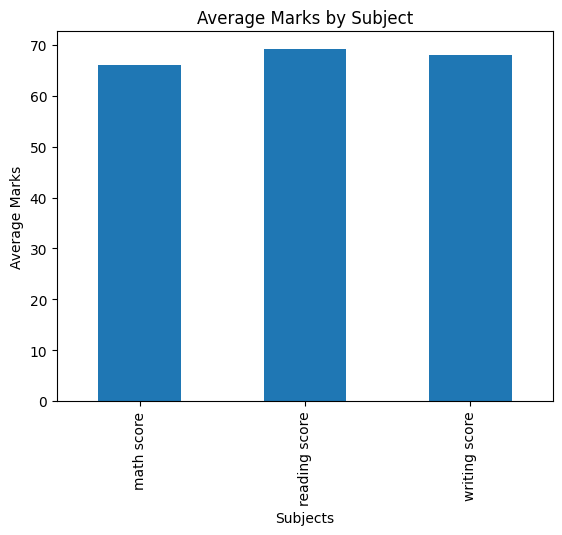

In [ ]:
# Subject-wise average marks

subject_avg = df_clean[
    ['math score', 'reading score', 'writing score']
].mean()

subject_avg.plot(kind='bar')

plt.title('Average Marks by Subject')
plt.xlabel('Subjects')
plt.ylabel('Average Marks')
plt.show()

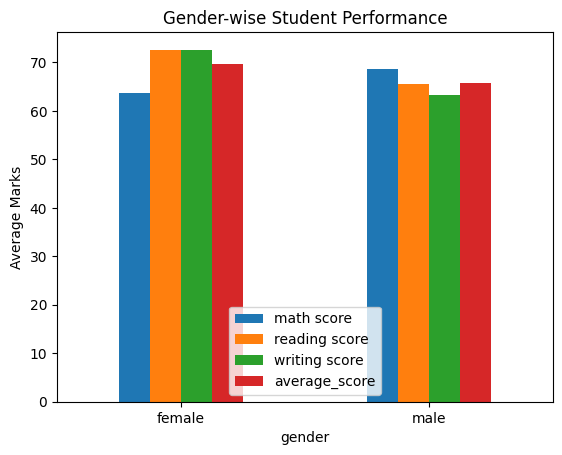

In [ ]:
# Gender-wise performance

gender_analysis.plot(kind='bar')

plt.title('Gender-wise Student Performance')
plt.ylabel('Average Marks')
plt.xticks(rotation=0)
plt.show()

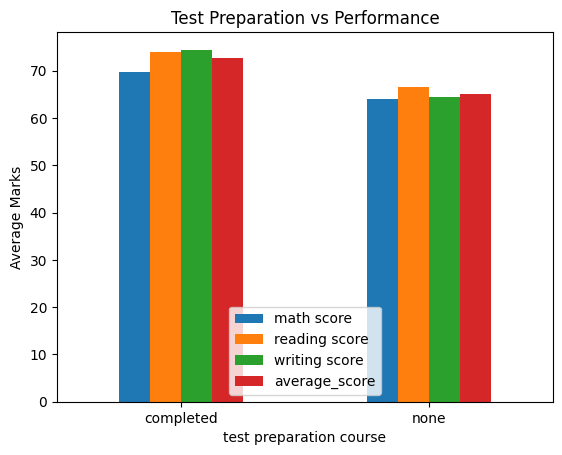

In [ ]:
# Test preparation comparison

preparation_analysis.plot(kind='bar')

plt.title('Test Preparation vs Performance')
plt.ylabel('Average Marks')
plt.xticks(rotation=0)
plt.show()

In [ ]:
# Create a 2×2 analysis dashboard

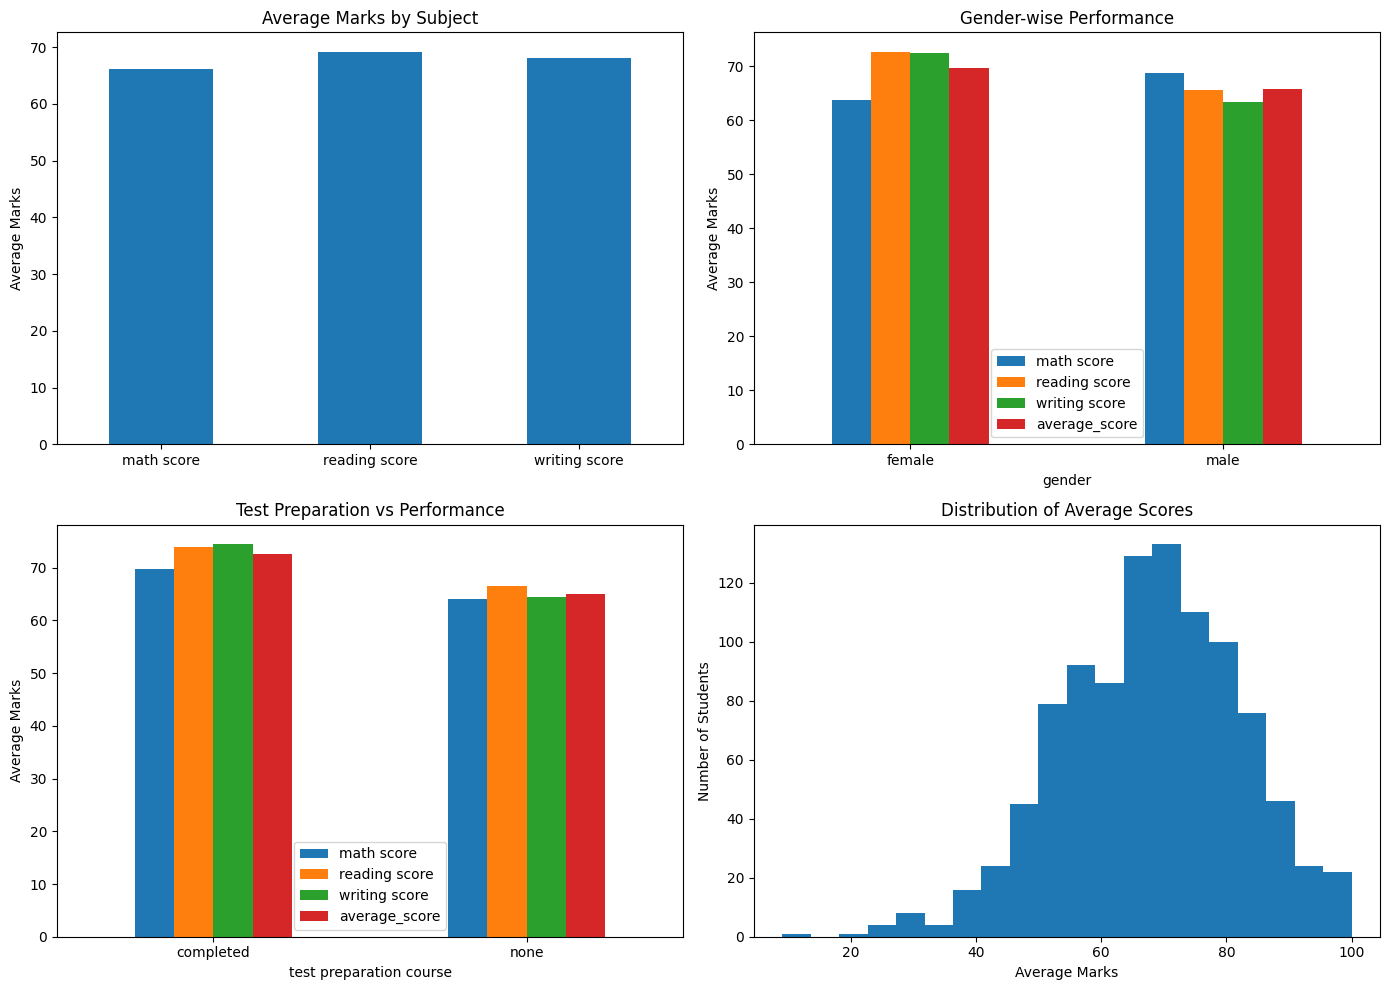

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Subject-wise average marks
subject_avg = df_clean[
    ['math score', 'reading score', 'writing score']
].mean()

subject_avg.plot(kind='bar', ax=axes[0, 0])
axes[0, 0].set_title('Average Marks by Subject')
axes[0, 0].set_ylabel('Average Marks')
axes[0, 0].tick_params(axis='x', rotation=0)

# 2. Gender-wise performance
gender_analysis.plot(kind='bar', ax=axes[0, 1])
axes[0, 1].set_title('Gender-wise Performance')
axes[0, 1].set_ylabel('Average Marks')
axes[0, 1].tick_params(axis='x', rotation=0)

# 3. Test preparation comparison
preparation_analysis.plot(kind='bar', ax=axes[1, 0])
axes[1, 0].set_title('Test Preparation vs Performance')
axes[1, 0].set_ylabel('Average Marks')
axes[1, 0].tick_params(axis='x', rotation=0)

# 4. Average score distribution
axes[1, 1].hist(df_clean['average_score'], bins=20)
axes[1, 1].set_title('Distribution of Average Scores')
axes[1, 1].set_xlabel('Average Marks')
axes[1, 1].set_ylabel('Number of Students')

plt.tight_layout()
plt.show()

In [ ]:
# Export your cleaned dataset

df_clean.to_csv('cleaned_student_data.csv', index=False)

In [ ]:
import os

os.makedirs('/kaggle/working/output', exist_ok=True)
os.makedirs('/kaggle/working/visualizations', exist_ok=True)

# Save cleaned dataset
df_clean.to_csv(
    '/kaggle/working/output/cleaned_student_data.csv',
    index=False
)

# Save dashboard
fig.savefig(
    '/kaggle/working/visualizations/student_dashboard.png',
    dpi=300,
    bbox_inches='tight'
)